# Model 2

## 1. Thu vien va cau hinh

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks, metrics
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
import os
import hashlib
from collections import Counter

# Cấu hình đường dẫn và siêu tham số (giữ nguyên từ file PyTorch)
DATA_DIR = Path("/home/pc/AAA/project/deepnn/G8_AI66A_DNN/data/raw")
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

SETS = ["train", "val", "test"]
IMG_SIZE = 128
BATCH_SIZE = 64
EPOCHS = 40
BASE_CH = 32
DROPOUT = 0.3
LABEL_SMOOTH = 0.1
MAX_LR = 2e-3
WEIGHT_DECAY = 5e-4


2026-10-13 20:28:22.824289: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-13 20:28:22.831881: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-13 20:28:22.841727: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-13 20:28:22.841749: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-13 20:28:22.848705: I tensorflow/core/platform/cpu_feature_gua

In [ ]:
# Bật Mixed Precision để tăng tốc độ huấn luyện trên GPU
tf.keras.mixed_precision.set_global_policy('mixed_float16')

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.16.2
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


2026-10-13 20:28:24.982417: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-10-13 20:28:25.004396: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-10-13 20:28:25.005709: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

## 1. Data preprocessing

In [ ]:
clean_samples = {se: [] for se in SETS}
seen_hash = {}
dup_count = Counter()

for se in ["test", "val", "train"]:
    se_dir = DATA_DIR / se
    if not se_dir.exists():
        continue
    for class_name in os.listdir(se_dir):
        class_dir = se_dir / class_name
        if not class_dir.is_dir():
            continue
            
        for img_path in class_dir.iterdir():
            if not img_path.is_file():
                continue
            
            with open(img_path, "rb") as f:
                file_hash = hashlib.md5(f.read()).hexdigest()
            
            if file_hash in seen_hash:
                kept_in = seen_hash[file_hash]
                dup_count[(se, kept_in)] += 1
            else:
                seen_hash[file_hash] = se
                clean_samples[se].append((img_path, class_name))
            
print("Ảnh trùng bị loại:", sum(dup_count.values()))
for (drop_in, kept_in), n in dup_count.items():
    print(f"- {n} ảnh ở '{drop_in}' trùng với ảnh ở '{kept_in}'")

del seen_hash 

Ảnh trùng bị loại: 7866
- 85 ảnh ở 'test' trùng với ảnh ở 'test'
- 345 ảnh ở 'val' trùng với ảnh ở 'test'
- 301 ảnh ở 'val' trùng với ảnh ở 'val'
- 2301 ảnh ở 'train' trùng với ảnh ở 'val'
- 1212 ảnh ở 'train' trùng với ảnh ở 'test'
- 3622 ảnh ở 'train' trùng với ảnh ở 'train'


In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, 
    image_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=BATCH_SIZE,
    label_mode="categorical", 
    shuffle=True, 
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, 
    image_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=BATCH_SIZE,
    label_mode="categorical", 
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, 
    image_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=BATCH_SIZE,
    label_mode="categorical", 
    shuffle=False
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print(f"Các lớp: {class_names}")

# Tính Mean và Std trên tập train
channel_sum = np.zeros(3, dtype=np.float64)
channel_squared_sum = np.zeros(3, dtype=np.float64)
pixel_count = 0

for images, _ in train_ds:
    images = tf.cast(images, tf.float32) / 255.0
    channel_sum += tf.reduce_sum(images, axis=[0, 1, 2]).numpy()
    channel_squared_sum += tf.reduce_sum(tf.square(images), axis=[0, 1, 2]).numpy()
    pixel_count += int(tf.shape(images)[0]) * IMG_SIZE * IMG_SIZE

MEAN = channel_sum / pixel_count
variance = channel_squared_sum / pixel_count - np.square(MEAN)
STD = np.sqrt(np.maximum(variance, 0.0))

print("Mean (R, G, B):", MEAN.tolist())
print("Std  (R, G, B):", STD.tolist())

Found 76515 files belonging to 4 classes.


2026-10-13 20:28:33.149839: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-10-13 20:28:33.151435: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-10-13 20:28:33.152549: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

Found 21861 files belonging to 4 classes.
Found 10933 files belonging to 4 classes.
Các lớp: ['CNV', 'DME', 'DRUSEN', 'NORMAL']
Mean (R, G, B): [0.18895403328482827, 0.18895403375845599, 0.18895403283612833]
Std  (R, G, B): [0.22028999145740644, 0.22028999177253966, 0.22028999099358762]


2026-10-13 20:28:37.621907: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [5]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

# Tính toán Class Weights để xử lý mất cân bằng dữ liệu
train_counts = np.zeros(NUM_CLASSES)
for _, labels in train_ds:
    # labels có dạng one-hot
    train_counts += np.sum(labels.numpy(), axis=0)

imb_ratio = train_counts.max() / max(train_counts.min(), 1)
print(f"Tỉ lệ mất cân bằng (max/min) ở train: {imb_ratio:.2f}")

if imb_ratio > 1.5:
    total_samples = np.sum(train_counts)
    class_weights = {i: total_samples / (NUM_CLASSES * count) for i, count in enumerate(train_counts)}
    print("Dùng class weights:", {k: round(v, 3) for k, v in class_weights.items()})
else:
    class_weights = None
    print("Dữ liệu tương đối cân bằng -> không dùng class weights")

Tỉ lệ mất cân bằng (max/min) ở train: 5.80
Dùng class weights: {0: 0.73, 1: 2.356, 2: 3.082, 3: 0.532}


2026-10-13 20:28:40.991352: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [ ]:
# Định nghĩa ResBlock
def ResBlock(x, out_ch, stride=1, use_bn=True):
    in_ch = x.shape[-1]
    shortcut = x

    # Shortcut 
    if stride != 1 or in_ch != out_ch:
        shortcut = layers.Conv2D(out_ch, 1, strides=stride, use_bias=False)(shortcut)
        if use_bn:
            shortcut = layers.BatchNormalization()(shortcut)

    # Conv 1
    y = layers.Conv2D(out_ch, 3, strides=stride, padding='same', use_bias=False)(x)
    if use_bn:
        y = layers.BatchNormalization()(y)
    y = layers.ReLU()(y)

    # Conv 2
    y = layers.Conv2D(out_ch, 3, strides=1, padding='same', use_bias=False)(y)
    if use_bn:
        y = layers.BatchNormalization()(y)

    
    y = layers.Add()([y, shortcut])
    y = layers.ReLU()(y)
    return y


# Xây dựng ResNet
def build_resnet(input_shape, num_classes, base_ch=32, dropout=0.3):
    inputs = layers.Input(shape=input_shape)

    # Data Augmentation (Tương đương transforms trong PyTorch)
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(15 / 360)(x)
    x = layers.RandomZoom((-0.1, 0.1))(x)
    x = layers.RandomBrightness(0.2)(x)
    x = layers.RandomContrast(0.2)(x)
    
    # Rescaling & Normalization
    x = layers.Rescaling(1.0 / 255)(x)
    x = layers.Normalization(axis=-1, mean=MEAN.astype("float32"), variance=np.square(STD.astype("float32")))(x)

    # Stem
    x = layers.Conv2D(base_ch, 3, strides=1, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Stage 1 (base_ch * 1)
    x = ResBlock(x, base_ch * 1, stride=1)
    x = ResBlock(x, base_ch * 1, stride=1)

    # Stage 2 (base_ch * 2)
    x = ResBlock(x, base_ch * 2, stride=2)
    x = ResBlock(x, base_ch * 2, stride=1)

    # Stage 3 (base_ch * 4)
    x = ResBlock(x, base_ch * 4, stride=2)
    x = ResBlock(x, base_ch * 4, stride=1)

    # Stage 4 (base_ch * 8)
    x = ResBlock(x, base_ch * 8, stride=2)
    x = ResBlock(x, base_ch * 8, stride=1)

    # Head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    
    # Output (Cast to float32 để tương thích mixed_precision)
    outputs = layers.Dense(num_classes, activation='softmax', dtype='float32')(x)

    return tf.keras.Model(inputs, outputs)

model = build_resnet((IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES, BASE_CH, DROPOUT)
model.summary()

2026-10-13 20:28:41.010512: E tensorflow/core/util/util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip         │ (None, 128, 128,  │          0 │ input_layer[0][0] │
│ (RandomFlip)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation     │ (None, 128, 128,  │          0 │ random_flip[0][0] │
│ (RandomRotation)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom         │ (None, 128, 128,  │          0 │ random_rotation[… │
│ (RandomZoom)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_brightness   │ (None, 128, 128,  │          0 │ random_zoom[0][0] │
│ (RandomBrightness)  │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_contrast     │ (None, 128, 128,  │          0 │ random_brightnes… │
│ (RandomContrast)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 128, 128,  │          0 │ random_contrast[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 128, 128,  │          0 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        864 │ normalization[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      9,216 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │      9,216 │ re_lu_1[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128, 128,  │          0 │ batch_normalizat

 Total params: 2,800,868 (10.68 MB)

 Trainable params: 2,796,068 (10.67 MB)

 Non-trainable params: 4,800 (18.75 KB)

In [7]:
# Sử dụng AdamW (hoặc Adam có weight_decay) và Label Smoothing
model.compile(
    optimizer=optimizers.Adam(learning_rate=MAX_LR, weight_decay=WEIGHT_DECAY),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTH),
    metrics=['accuracy', metrics.F1Score(average='macro', name='f1_score')]
)

# Callbacks (Thay thế cho OneCycleLR và Early stopping thủ công)
cb_list = [
    callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
    callbacks.ModelCheckpoint('model2_resnet.keras', monitor='val_loss', save_best_only=True)
]

In [8]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=cb_list,
    class_weight=class_weights
)

Epoch 1/40


/home/pc/miniconda3/envs/pytorch_gpu/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-10-13 20:28:46.461834: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907


1196/1196 ━━━━━━━━━━━━━━━━━━━━ 202s 162ms/step - accuracy: 0.6860 - f1_score: 0.6055 - loss: 0.9625 - val_accuracy: 0.6019 - val_f1_score: 0.5565 - val_loss: 1.3785 - learning_rate: 0.0020
Epoch 2/40
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 187s 156ms/step - accuracy: 0.8875 - f1_score: 0.8316 - loss: 0.6231 - val_accuracy: 0.9191 - val_f1_score: 0.8749 - val_loss: 0.5514 - learning_rate: 0.0020
Epoch 3/40
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 187s 156ms/step - accuracy: 0.9118 - f1_score: 0.8646 - loss: 0.5687 - val_accuracy: 0.9097 - val_f1_score: 0.8499 - val_loss: 0.5840 - learning_rate: 0.0020
Epoch 4/40
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 179s 150ms/step - accuracy: 0.9187 - f1_score: 0.8741 - loss: 0.5495 - val_accuracy: 0.8996 - val_f1_score: 0.8497 - val_loss: 0.5985 - learning_rate: 0.0020
Epoch 5/40
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 186s 155ms/step - accuracy: 0.9265 - f1_score: 0.8853 - loss: 0.5315 - val_accuracy: 0.9092 - val_f1_score: 0.8611 - val_loss: 0.5716 - learning_rate: 0.0020
Epoch 6/40


In [10]:
# Lấy ground truth và predictions
y_true = np.concatenate([y for x, y in test_ds], axis=0)
y_true = np.argmax(y_true, axis=1)

y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

acc = np.mean(y_true == y_pred)
p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
_, _, f1_weighted, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)

print(f"Test accuracy : {acc:.4f}")
print(f"Macro precision/recall/F1: {p_macro:.4f} / {r_macro:.4f} / {f1_macro:.4f}")
print(f"Weighted F1   : {f1_weighted:.4f}\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))

2026-10-13 22:30:59.899975: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


171/171 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step
Test accuracy : 0.9672
Macro precision/recall/F1: 0.9361 / 0.9571 / 0.9456
Weighted F1   : 0.9677

              precision    recall  f1-score   support

         CNV     0.9898    0.9576    0.9734      3746
         DME     0.9459    0.9483    0.9471      1161
      DRUSEN     0.8248    0.9391    0.8782       887
      NORMAL     0.9840    0.9833    0.9836      5139

    accuracy                         0.9672     10933
   macro avg     0.9361    0.9571    0.9456     10933
weighted avg     0.9690    0.9672    0.9677     10933



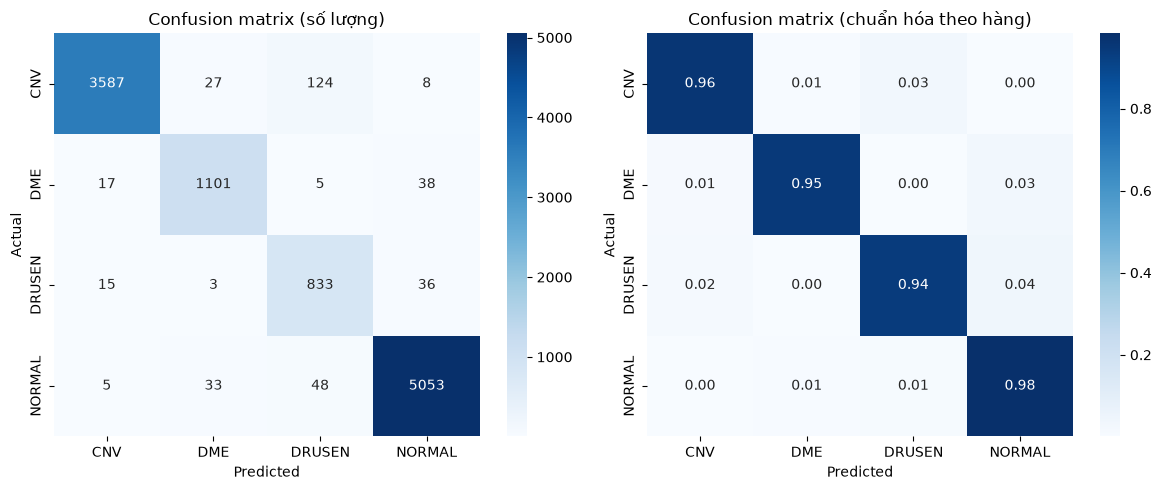

In [11]:
# Vẽ Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0], xticklabels=class_names, yticklabels=class_names)
ax[0].set_title('Confusion matrix (số lượng)')
ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual')

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', ax=ax[1], xticklabels=class_names, yticklabels=class_names)
ax[1].set_title('Confusion matrix (chuẩn hóa theo hàng)')
ax[1].set_xlabel('Predicted'); ax[1].set_ylabel('Actual')
plt.tight_layout()
plt.show()